In [127]:
import matplotlib.pyplot as plt
import pandas as pd
import cv2
import numpy as np
from ultralytics import YOLO 

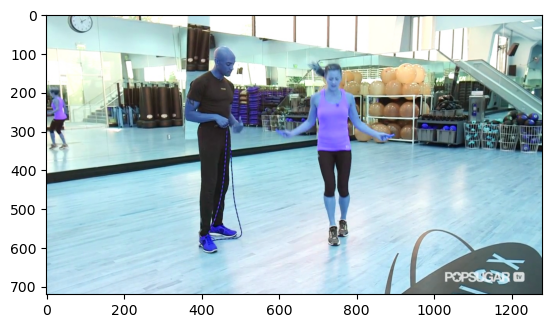

In [128]:
plt.imshow(cv2.imread("Datasets/images/000003072.jpg"))


In [129]:
def resize_with_padding(points,image, target_size=(224, 224), padding_color=(0, 0, 0)):
    h, w = image.shape[:2]
    target_w, target_h = target_size

    # Compute the scaling factor
    scale = min(target_w / w, target_h / h)
    new_w, new_h = int(w * scale), int(h * scale)

    # Resize while maintaining aspect ratio
    resized = cv2.resize(image, (new_w, new_h), interpolation=cv2.INTER_AREA)

    # Create a new blank image (padded) with the target size
    padded_image = np.full((target_h, target_w, 3), padding_color, dtype=np.uint8)
    #ajust points
    points = [(int(x * scale + (target_w - new_w) // 2), int(y * scale + (target_h - new_h) // 2)) for x, y in points]
        
    # Compute padding (center the image)
    x_offset = (target_w - new_w) // 2
    y_offset = (target_h - new_h) // 2

    # Place the resized image onto the padded canvas
    padded_image[y_offset:y_offset + new_h, x_offset:x_offset + new_w] = resized

    return padded_image,points

In [130]:
def get_persons(image,points):
    yolo = YOLO("yolov8n.pt")
    results = yolo(image)
    max = 0
    crop = 0,0,0,0
     # Get detected objects
    i = 0
    for result in results:
        for box in result.boxes:
            cls = int(box.cls[0].item())  # Get class ID
            if cls == 0:  # Class '0' is "person" in COCO dataset
                x1, y1, x2, y2 = map(int, box.xyxy[0].tolist())  #
                if i == 0:
                    crop = x1,y1,x2,y2
                    i = 1
                #if this area contains all the points of the person
                sumed = sum([x1 <= x <= x2 and y1 <= y <= y2 for x, y in points])
                if sumed > max:
                    #plt.imshow(cropped_image)
                    max = sumed
                    crop = x1,y1,x2,y2
    return crop

In [131]:
def transform_data(name,points):
    image = cv2.imread("Datasets/images/"+name)
    leftmost,bottommost,rightmost,topmost = get_persons(image,points)
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    # Ensure the coordinates are within the image bounds
    leftmost = max(leftmost, 0)
    bottommost = max(bottommost, 0)
    rightmost = min(rightmost, image.shape[1])
    topmost = min(topmost, image.shape[0])

    # Cut image from the points
    image = image[bottommost:topmost, leftmost:rightmost]

    # Adjust points coordinates
    points = [(x - leftmost, y - bottommost) for x, y in points]

    return resize_with_padding(points,image)
    # Plot image
    


0: 384x640 3 persons, 1 clock, 54.3ms
Speed: 2.0ms preprocess, 54.3ms inference, 1.0ms postprocess per image at shape (1, 3, 384, 640)


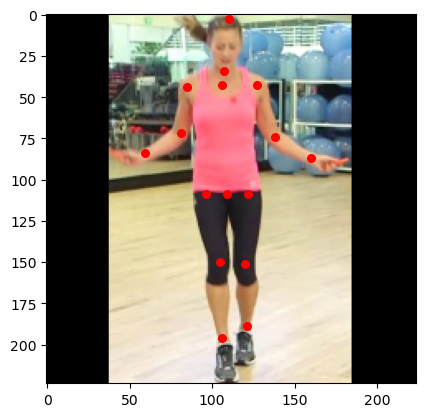

In [132]:


df = pd.read_csv('./Datasets/mpii_human_pose.csv')
df = df[df["NAME"]=="000003072.jpg"]
# Load image using OpenCV (convert BGR to RGB for Matplotlib)

keypoints = [
    ("r ankle_X", "r ankle_Y"),
    ("r knee_X", "r knee_Y"),
    ("r hip_X", "r hip_Y"),
    ("l hip_X", "l hip_Y"),
    ("l knee_X", "l knee_Y"),
    ("l ankle_X", "l ankle_Y"),
    ("pelvis_X", "pelvis_Y"),
    ("thorax_X", "thorax_Y"),
    ("upper neck_X", "upper neck_Y"),
    ("head top_X", "head top_Y"),
    ("r wrist_X", "r wrist_Y"),
    ("r elbow_X", "r elbow_Y"),
    ("r shoulder_X", "r shoulder_Y"),
    ("l shoulder_X", "l shoulder_Y"),
    ("l elbow_X", "l elbow_Y"),
    ("l wrist_X", "l wrist_Y")
]

# Select the first row (example: first image)
row = df.iloc[0]  # Change index for other images

# Convert keypoints into a list of (x, y) tuples
points = [(int(row[x]), int(row[y])) for x, y in keypoints]

image,points = transform_data("000003072.jpg",points)
# Plot image
plt.imshow(image)
for (x, y) in points:
    plt.scatter(x, y, color="red", s=30)  # Red points

plt.show()

In [133]:
# change the dataset using a function that will return the image with the alterations and the new points
def process_row(row):
    points = [(int(row[x]), int(row[y])) for x, y in keypoints]
    try:
        image, points = transform_data(row["NAME"], points)
    except Exception as e:
        print(f"Error processing row {row['ID']}: {e}")
        return None
    row["r ankle_X"], row["r ankle_Y"] = points[0]
    row["r knee_X"], row["r knee_Y"] = points[1]
    row["r hip_X"], row["r hip_Y"] = points[2]
    row["l hip_X"], row["l hip_Y"] = points[3]
    row["l knee_X"], row["l knee_Y"] = points[4]
    row["l ankle_X"], row["l ankle_Y"] = points[5]
    row["pelvis_X"], row["pelvis_Y"] = points[6]
    row["thorax_X"], row["thorax_Y"] = points[7]
    row["upper neck_X"], row["upper neck_Y"] = points[8]
    row["head top_X"], row["head top_Y"] = points[9]
    row["r wrist_X"], row["r wrist_Y"] = points[10]
    row["r elbow_X"], row["r elbow_Y"] = points[11]
    row["r shoulder_X"], row["r shoulder_Y"] = points[12]
    row["l shoulder_X"], row["l shoulder_Y"] = points[13]
    row["l elbow_X"], row["l elbow_Y"] = points[14]
    row["l wrist_X"], row["l wrist_Y"] = points[15]
    row["NAME"] = image
    
    return row


0: 384x640 4 persons, 1 frisbee, 71.7ms
Speed: 1.5ms preprocess, 71.7ms inference, 1.0ms postprocess per image at shape (1, 3, 384, 640)

0: 384x640 2 persons, 1 bicycle, 56.6ms
Speed: 1.0ms preprocess, 56.6ms inference, 1.3ms postprocess per image at shape (1, 3, 384, 640)

0: 384x640 1 person, 56.4ms
Speed: 2.0ms preprocess, 56.4ms inference, 0.0ms postprocess per image at shape (1, 3, 384, 640)

0: 384x640 5 persons, 1 skateboard, 58.1ms
Speed: 2.0ms preprocess, 58.1ms inference, 1.4ms postprocess per image at shape (1, 3, 384, 640)

0: 384x640 1 person, 1 frisbee, 1 surfboard, 1 bottle, 67.1ms
Speed: 2.0ms preprocess, 67.1ms inference, 1.0ms postprocess per image at shape (1, 3, 384, 640)

0: 480x640 2 persons, 1 cup, 2 chairs, 64.2ms
Speed: 0.0ms preprocess, 64.2ms inference, 0.0ms postprocess per image at shape (1, 3, 480, 640)

0: 384x640 2 persons, 1 bench, 1 chair, 50.3ms
Speed: 1.1ms preprocess, 50.3ms inference, 0.0ms postprocess per image at shape (1, 3, 384, 640)

0: 384x

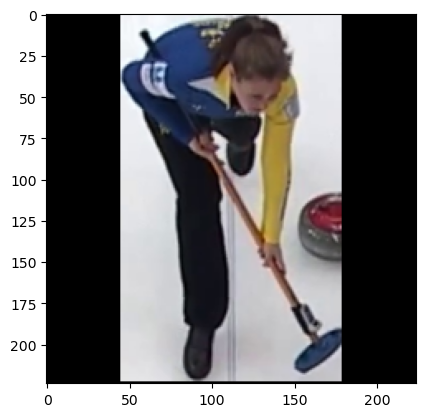

In [134]:
df = pd.read_csv('./Datasets/mpii_human_pose.csv')
df= df[(df != -1).all(axis=1)]
df = df.head(2000).apply(process_row, axis=1)

plt.imshow(df.iloc[0]["NAME"])


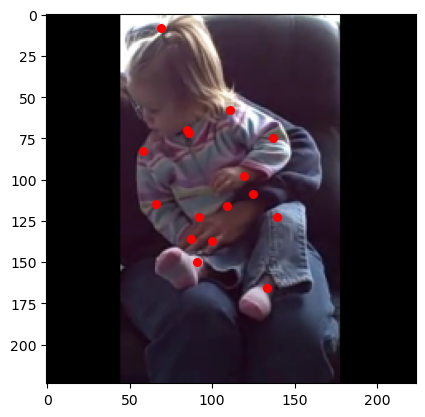

In [140]:
row = df.iloc[5]  # Change index for other images
# Convert keypoints into a list of (x, y) tuples
points = [(int(row[x]), int(row[y])) for x, y in keypoints]
plt.imshow(row["NAME"])
for (x, y) in points:
    plt.scatter(x, y, color="red", s=30)  # Red points

In [ ]:
df.to_pickle('dataset.pkl')